# Notebook 04: Quantum Emergence

**Goal:** Show explicitly that a qubit density matrix maps to a stochastic state,
that quantum evolution produces an indivisible process, and that the Born rule
emerges naturally.

By the end of this notebook you will be able to:
- Convert a density matrix to a stochastic state vector
- Verify that qubit evolution is indivisible
- Compute measurement probabilities via the Born rule

---
> ### 📓 Annotated study copy
>
> Working copy of `04_quantum_emergence.ipynb`. Added sections are marked
> **📖 In depth** and **🔍 Reading the code**. The original is unchanged.
>
> Contains extended treatments of the **density matrix**, the **trace**, and
> **unitarity** — the three pieces of quantum formalism this notebook uses without
> defining. Also flags two overstatements in the original:
>
> | claim | status |
> |---|---|
> | *"Qubit evolution under **any** non-trivial Hamiltonian produces an indivisible process"* | **false** — $H \propto \sigma_z$ gives $\lvert U\rvert^2 = I$ at all times, perfectly divisible. Counterexample included below. |
> | *"The Born rule … follows from the stochastic structure"* (as demonstrated here) | the cell shows **agreement**, not derivation — $\mathrm{Tr}(M_0\rho) = \rho_{00}$ is true by inspection for projectors onto basis states |
>
> Companion to the annotated copies of notebooks 01–03.
---

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from isp.quantum import (
    density_matrix_to_stochastic_state,
    unitary_to_transition_matrix,
    make_qubit_sigmax_process,
    born_rule,
)
from isp.divisibility import check_divisibility, indivisibility_signature
from isp.visualization import plot_transition_matrix, plot_probability_evolution

## 1. Density Matrix → Stochastic State

A qubit density matrix $\rho$ encodes a probability distribution via its diagonal.
The diagonal entries $\rho_{ii}$ are the Born-rule probabilities for the
computational basis.

### 📖 In depth: what a density matrix *is*

The notebook uses $\rho$ without defining it. Since the entire stochastic-quantum correspondence is a statement about what $\rho$ really encodes, it's worth being precise.

#### The problem it solves

A state vector $|\psi\rangle$ describes a system you know **completely** — a *pure* state. But you often don't. Two very different situations both need describing:

| | | |
|---|---|---|
| **Superposition** (pure) | $\lvert\psi\rangle = \tfrac{1}{\sqrt2}(\lvert 0\rangle + \lvert 1\rangle)$ | the system *is* in both, coherently |
| **Mixture** (classical ignorance) | 50% chance $\lvert0\rangle$, 50% chance $\lvert1\rangle$ | the system *is* in one, you don't know which |

Both give 50/50 measurement statistics in the computational basis. **They are physically different** — the superposition interferes, the mixture doesn't — and no single state vector can express the second. The density matrix handles both:

$$\rho \;=\; \sum_k p_k \,\lvert\psi_k\rangle\langle\psi_k\rvert$$

a probability-weighted sum of projectors. For the two cases above:

$$\rho_{\text{pure}} = \frac{1}{2}\begin{pmatrix}1 & 1\\ 1 & 1\end{pmatrix}
\qquad\qquad
\rho_{\text{mixed}} = \frac{1}{2}\begin{pmatrix}1 & 0\\ 0 & 1\end{pmatrix}$$

Same diagonal. **Different off-diagonal.** That difference is the whole story.

#### Reading the entries

$$\rho = \begin{pmatrix} \rho_{00} & \rho_{01} \\ \rho_{10} & \rho_{11}\end{pmatrix}
= \begin{pmatrix} \textbf{populations} & \textbf{coherences} \\ \textbf{coherences} & \textbf{populations}\end{pmatrix}$$

* **Diagonal — populations.** $\rho_{ii} = P(\text{measure state } i)$. Real, non-negative, sums to 1. *This is the stochastic state vector* $\mathbf{p}$.
* **Off-diagonal — coherences.** $\rho_{01} = \overline{\rho_{10}}$, complex. These carry the *relative phase* between basis states. They have no classical counterpart, they are what interferes, and **they are exactly what `density_matrix_to_stochastic_state()` throws away.**

#### The three defining conditions

A matrix is a valid density matrix iff:

| condition | meaning | in the code |
|---|---|---|
| $\rho = \rho^\dagger$ (Hermitian) | probabilities and observables come out real | $\rho_{10} = \overline{\rho_{01}}$ in the cell below |
| $\rho \succeq 0$ (positive semidefinite) | no negative probabilities, in *any* basis | `np.linalg.eigvalsh(rho)` $\geq 0$ |
| $\mathrm{Tr}\,\rho = 1$ | normalization | `np.trace(rho)` $= 1$ |

Positive semidefiniteness is the strong one. Non-negative *diagonal* entries are easy; requiring **every eigenvalue** $\geq 0$ means the probabilities stay non-negative no matter which basis you rotate into. It is the quantum generalization of "entries of $\mathbf{p}$ are $\geq 0$" — and note the parallel to notebook 01, where non-negativity was likewise the hard condition and normalization the easy one.

#### Pure vs. mixed, quantitatively

$$\mathrm{Tr}(\rho^2) = \begin{cases} 1 & \text{pure} \\ < 1 & \text{mixed}\end{cases}
\qquad\qquad \mathrm{Tr}(\rho^2) \geq \tfrac{1}{d} \text{ always}$$

The state in the next cell has $\mathrm{Tr}(\rho^2) = 0.68$ — genuinely mixed, but retaining substantial coherence.

#### 🔭 Why this matters for the ISP framework

`density_matrix_to_stochastic_state()` is `np.real(np.diag(rho))` — it keeps the populations and discards the coherences. **The map is lossy, and deliberately so.** Barandes' claim is not that $\rho$ *is* the stochastic state; it's that the full content of $\rho$ — coherences included — is recoverable from the *indivisibility* of the resulting process. The phase information doesn't vanish; it reappears as the negative entries in the intermediate matrices. Notebook 03 showed the arithmetic: those cross terms are precisely the discarded off-diagonals making themselves felt.

### 📖 In depth: the trace — why quantum mechanics is built out of it

The cell below prints `np.trace(rho)` and says "must be 1.0", and section 3 writes the Born rule as $\mathrm{Tr}(M\rho)$. The trace is doing far more work than "add up the diagonal" suggests.

#### Definition, and the property that matters

$$\mathrm{Tr}(A) \;=\; \sum_i A_{ii}$$

Trivial arithmetic. But:

$$\boxed{\;\mathrm{Tr}(A) \;=\; \sum_i \lambda_i \;=\; \text{the sum of the eigenvalues}\;}$$

which means **the trace does not depend on the basis you happen to be writing the matrix in.** Rotate to any other orthonormal basis and every individual entry changes, while the trace does not:

$$\mathrm{Tr}(S^{-1}AS) = \mathrm{Tr}(A)$$

This is *the* reason the trace is everywhere in quantum mechanics. A physical prediction must not depend on an arbitrary choice of coordinates. Any quantity you can write as a trace is automatically basis-independent, hence a candidate for something physically real. The diagonal of $\rho$, by contrast, is basis-*dependent* — which is exactly why `density_matrix_to_stochastic_state()` is a lossy, basis-relative operation, and why notebook 03's indivisibility signature inherits a preferred basis.

#### The cyclic property

$$\mathrm{Tr}(ABC) = \mathrm{Tr}(BCA) = \mathrm{Tr}(CAB)$$

You may rotate the order cyclically (not arbitrarily — $\mathrm{Tr}(ABC) \neq \mathrm{Tr}(BAC)$ in general). Basis-independence follows immediately: $\mathrm{Tr}(S^{-1}AS) = \mathrm{Tr}(ASS^{-1}) = \mathrm{Tr}(A)$.

#### The four jobs the trace does here

**1. Normalization.** $\mathrm{Tr}\,\rho = \sum_i \rho_{ii} = \sum_i P(\text{outcome } i) = 1$. The quantum version of "the probability vector sums to 1" — and being basis-independent, it holds in *every* basis at once, which the plain column-sum condition of notebook 01 does not.

**2. Expectation values.** For an observable $A$: $\;\langle A\rangle = \mathrm{Tr}(A\rho)$. One formula covering pure and mixed states alike.

**3. The Born rule.** $P(\text{outcome}) = \mathrm{Tr}(M\rho)$ — section 3 below. With $M_0 = |0\rangle\langle 0|$ a projector, this collapses to $\rho_{00}$, which is why the code's check comes out exactly equal to the diagonal.

**4. Conservation of probability under evolution.** This is the one that ties back to the whole lab. Under unitary evolution $\rho \mapsto U\rho U^\dagger$, cyclicity gives

$$\mathrm{Tr}(U\rho U^\dagger) = \mathrm{Tr}(\rho\, U^\dagger U) = \mathrm{Tr}(\rho\,I) = \mathrm{Tr}(\rho) = 1$$

**Probability is conserved automatically, for free, as an algebraic identity.** Compare notebook 01, where the same guarantee required imposing $\mathbf{1}^T T = \mathbf{1}^T$ by hand. Here it follows from $U^\dagger U = I$ plus the cyclic property. Same physical content, obtained structurally rather than by assumption.

#### One more, worth knowing about

The **partial trace** $\rho_A = \mathrm{Tr}_B(\rho_{AB})$ traces out a subsystem, answering "what does $A$ alone look like if I ignore $B$?" It is how entanglement produces mixed states from pure ones, and how decoherence is described. Beyond this notebook's two-state examples, but it is the operation doing the work in every discussion of measurement and the emergence of classicality.

In [2]:
# Mixed qubit state: 70% |0⟩, 30% |1⟩, with coherences
rho = np.array([[0.7,  0.1 + 0.2j],
                [0.1 - 0.2j,  0.3]])

print("Density matrix ρ:")
print(rho)
print(f"\nTrace: {np.trace(rho).real:.4f}  (must be 1.0)")
print(f"Eigenvalues (must be ≥ 0): {np.linalg.eigvalsh(rho).round(4)}")

p = density_matrix_to_stochastic_state(rho)
print(f"\nStochastic state vector p = {p}")
print(f"Sum: {p.sum():.4f}")

Density matrix ρ:
[[0.7+0.j  0.1+0.2j]
 [0.1-0.2j 0.3+0.j ]]

Trace: 1.0000  (must be 1.0)
Eigenvalues (must be ≥ 0): [0.2 0.8]

Stochastic state vector p = [0.7 0.3]
Sum: 1.0000


In [3]:
# 📖 In depth: density matrix and trace properties, verified.

np.set_printoptions(precision=4, suppress=True)

# --- superposition vs. mixture: same diagonal, different physics -----------
rho_pure  = 0.5 * np.array([[1, 1], [1, 1]], dtype=complex)   # |+><+|
rho_mixed = 0.5 * np.array([[1, 0], [0, 1]], dtype=complex)   # 50/50 ignorance

print("SUPERPOSITION vs MIXTURE — identical measurement statistics:")
print(f"  pure  diag = {np.real(np.diag(rho_pure))}   mixed diag = {np.real(np.diag(rho_mixed))}")
print(f"  but coherences differ: pure rho_01 = {rho_pure[0,1]:.2f}, "
      f"mixed rho_01 = {rho_mixed[0,1]:.2f}")
print(f"  purity Tr(rho^2): pure = {np.trace(rho_pure@rho_pure).real:.4f}  "
      f"mixed = {np.trace(rho_mixed@rho_mixed).real:.4f}")
print("  -> the diagonal cannot tell them apart; the off-diagonal can.\n")

# --- the three defining conditions, on this notebook's rho ----------------
print("THE THREE CONDITIONS on rho:")
print(f"  Hermitian?           {np.allclose(rho, rho.conj().T)}")
print(f"  eigenvalues >= 0?    {np.linalg.eigvalsh(rho).round(4)}  -> "
      f"{np.all(np.linalg.eigvalsh(rho) >= -1e-12)}")
print(f"  Tr(rho) == 1?        {np.trace(rho).real:.6f}")
print(f"  purity Tr(rho^2)   = {np.trace(rho@rho).real:.4f}  (< 1 -> mixed)\n")

# --- the trace is BASIS-INDEPENDENT; the diagonal is not ------------------
H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)      # Hadamard: change of basis
rho_rotated = H @ rho @ H.conj().T

print("BASIS INDEPENDENCE — rotate into the Hadamard basis:")
print(f"  original diagonal : {np.real(np.diag(rho))}")
print(f"  rotated  diagonal : {np.real(np.diag(rho_rotated))}   <-- CHANGED")
print(f"  original trace    : {np.trace(rho).real:.6f}")
print(f"  rotated  trace    : {np.trace(rho_rotated).real:.6f}   <-- UNCHANGED")
print(f"  eigenvalues also unchanged: {np.linalg.eigvalsh(rho_rotated).round(4)}")
print("  -> 'the' stochastic state depends on basis; the trace does not.\n")

# --- cyclic property, and why unitary evolution conserves probability -----
A = np.random.rand(2, 2); B = np.random.rand(2, 2); C = np.random.rand(2, 2)
print("CYCLIC PROPERTY:")
print(f"  Tr(ABC) = {np.trace(A@B@C):.6f}")
print(f"  Tr(BCA) = {np.trace(B@C@A):.6f}   <-- equal (cyclic)")
print(f"  Tr(BAC) = {np.trace(B@A@C):.6f}   <-- NOT equal (not a cyclic rotation)\n")

theta = 0.9
U = np.array([[np.cos(theta), -1j*np.sin(theta)],
              [-1j*np.sin(theta), np.cos(theta)]])
rho_t = U @ rho @ U.conj().T
print("PROBABILITY CONSERVATION comes free from cyclicity:")
print(f"  U unitary?  U^dag U = I : {np.allclose(U.conj().T @ U, np.eye(2))}")
print(f"  Tr(U rho U^dag) = {np.trace(rho_t).real:.6f}   (still exactly 1)")
print(f"  populations changed: {np.real(np.diag(rho)).round(4)} -> "
      f"{np.real(np.diag(rho_t)).round(4)}, but the trace did not.")

SUPERPOSITION vs MIXTURE — identical measurement statistics:
  pure  diag = [0.5 0.5]   mixed diag = [0.5 0.5]
  but coherences differ: pure rho_01 = 0.50+0.00j, mixed rho_01 = 0.00+0.00j
  purity Tr(rho^2): pure = 1.0000  mixed = 0.5000
  -> the diagonal cannot tell them apart; the off-diagonal can.

THE THREE CONDITIONS on rho:
  Hermitian?           True
  eigenvalues >= 0?    [0.2 0.8]  -> True
  Tr(rho) == 1?        1.000000
  purity Tr(rho^2)   = 0.6800  (< 1 -> mixed)

BASIS INDEPENDENCE — rotate into the Hadamard basis:
  original diagonal : [0.7 0.3]
  rotated  diagonal : [0.6 0.4]   <-- CHANGED
  original trace    : 1.000000
  rotated  trace    : 1.000000   <-- UNCHANGED
  eigenvalues also unchanged: [0.2 0.8]
  -> 'the' stochastic state depends on basis; the trace does not.

CYCLIC PROPERTY:
  Tr(ABC) = 1.905115
  Tr(BCA) = 1.905115   <-- equal (cyclic)
  Tr(BAC) = 1.854258   <-- NOT equal (not a cyclic rotation)

PROBABILITY CONSERVATION comes free from cyclicity:
  U unita

## 2. Quantum Evolution Is Indivisible

The sigma_x qubit process is indivisible. Let's verify this formally
and measure how deep into quantum territory it sits.

### 📖 In depth: unitarity — and why it is what makes a stochastic matrix appear at all

#### The definition

A matrix $U$ is **unitary** if

$$U^\dagger U = U U^\dagger = I, \qquad\text{where } U^\dagger = \overline{U}^{\,T}$$

Equivalently: $U^{-1} = U^\dagger$. Inverting is as cheap as conjugate-transposing.

#### Four equivalent ways to say the same thing

| statement | meaning |
|---|---|
| $U^\dagger U = I$ | the algebraic definition |
| $\langle U\psi \mid U\phi\rangle = \langle \psi\mid\phi\rangle$ | **inner products preserved** — angles and lengths unchanged |
| $\lVert U\psi\rVert = \lVert\psi\rVert$ | **norms preserved** — total probability conserved |
| columns of $U$ are orthonormal | each column is a unit vector, mutually perpendicular |

Geometrically: a unitary is a **rigid rotation of Hilbert space**. Nothing is stretched, squashed, or lost — the state vector is turned, not deformed. Two immediate consequences:

* **Reversibility.** $U^{-1} = U^\dagger$ always exists, so quantum evolution never destroys information. (Measurement is the non-unitary step, which is why it's the contentious one.)
* **Eigenvalues lie on the unit circle**, $|\lambda| = 1$, so they are pure phases $e^{i\theta}$. Unitary evolution *rotates phases*; it does not grow or damp anything.

#### Where unitaries come from: $U = e^{-iHt}$

Given a Hermitian $H$ (the Hamiltonian, $H = H^\dagger$),

$$U(t) = e^{-iHt} \quad\text{is unitary for every } t$$

because $U^\dagger U = e^{+iH^\dagger t}e^{-iHt} = e^{+iHt}e^{-iHt} = I$. **Hermitian generator $\Rightarrow$ unitary evolution** (Stone's theorem, in the finite-dimensional case).

> 🔭 **Compare notebook 01.** There, a valid generator $L$ (columns summing to zero) produced a valid transition matrix $T = e^{L\Delta t}$ via the *matrix exponential*. Here, a valid generator $H$ (Hermitian) produces a valid evolution $U = e^{-iHt}$ via the *same matrix exponential*. Identical structure, one condition swapped:
> $$\mathbf{1}^T L = \mathbf{0}^T \;\longleftrightarrow\; H = H^\dagger$$
> Both are "the generator condition that keeps probability conserved for all time." This parallel is not decoration — it is the formal skeleton of the stochastic-quantum correspondence.

#### ⭐ The punchline: unitarity is exactly the column-sum rule in disguise

`unitary_to_transition_matrix()` is one line: `np.abs(U)**2`. Why is the result a valid stochastic matrix? Because of unitarity, and nothing else:

$$\sum_i T_{ij} \;=\; \sum_i |U_{ij}|^2 \;=\; \sum_i \overline{U_{ij}}\,U_{ij} \;=\; (U^\dagger U)_{jj} \;=\; I_{jj} \;=\; 1$$

**The columns of $\lvert U\rvert^2$ sum to 1 precisely because the columns of $U$ are unit vectors.** Non-negativity is free — a squared modulus cannot be negative.

So notebook 01's founding requirement, *"each column of a transition matrix must sum to 1,"* is — on the quantum side — literally the statement $U^\dagger U = I$. That is why a qubit yields an honest stochastic process at all, and it is the hinge the entire correspondence turns on. The next cell verifies it entry by entry.

#### ⚠️ Correcting the summary's claim

The notebook's summary states that qubit evolution under **any** non-trivial Hamiltonian produces an indivisible process. That is **false**, and the counterexample is one line: take $H \propto \sigma_z$. Then $U(t) = \mathrm{diag}(e^{-i\omega t/2}, e^{+i\omega t/2})$ is diagonal, so

$$\big|U(t)\big|^2 = \begin{pmatrix}1 & 0\\ 0 & 1\end{pmatrix} \quad\text{for every } t$$

— the identity, which is perfectly divisible with signature exactly 0. A $\sigma_z$ Hamiltonian generates genuine dynamics (it rotates phases, and those phases are physically detectable in *other* bases), but it commutes with the measurement basis, so it moves no population and the induced stochastic process is trivial.

The correct statement: **indivisibility requires a Hamiltonian that does not commute with the measurement basis.** Non-commutativity, not mere non-triviality. This is the same basis-dependence flagged in notebook 03's annotations, showing up as a concrete failure of an overgeneralized claim.

In [4]:
times = np.linspace(0, 2 * np.pi, 8).tolist()
proc = make_qubit_sigmax_process(omega=1.0, times=times)

result = check_divisibility(proc)
sig = indivisibility_signature(proc)

print(f"Divisible: {result['divisible']}")
print(f"Failure mode: {result['failure_mode']}")
print(f"Indivisibility signature: {sig:.4f}")

Divisible: False
Failure mode: negative_entries
Indivisibility signature: 1.7470


In [5]:
# 📖 In depth: unitarity IS the column-sum rule; and the sigma_z counterexample.
from scipy.linalg import expm

sigma_x = np.array([[0, 1], [1,  0]], dtype=complex)
sigma_z = np.array([[1, 0], [0, -1]], dtype=complex)

def U_of(H, t):
    return expm(-1j * H * t)

# --- unitarity => columns of |U|^2 sum to 1 -------------------------------
print("UNITARITY IS THE COLUMN-SUM RULE")
U = U_of(0.5 * sigma_x, 1.7)
T = unitary_to_transition_matrix(U)
print(f"  U =\n{np.round(U, 4)}")
print(f"  U^dag U == I ?  {np.allclose(U.conj().T @ U, np.eye(2))}")
print(f"  |U|^2 =\n{np.round(T, 4)}")
print(f"  column sums of |U|^2 = {T.sum(axis=0)}")
print(f"  diagonal of U^dag U  = {np.real(np.diag(U.conj().T @ U))}   <-- the SAME numbers")
print("  sum_i |U_ij|^2 = (U^dag U)_jj = 1.  The column-sum rule of notebook 01")
print("  is literally the statement U^dag U = I.\n")

# --- the sigma_z counterexample to "ANY non-trivial Hamiltonian" ----------
print("COUNTEREXAMPLE to 'any non-trivial Hamiltonian is indivisible':")
for t in [0.5, 1.3, 2.7, 4.0]:
    Uz = U_of(0.5 * sigma_z, t)
    Tz = unitary_to_transition_matrix(Uz)
    print(f"  t={t:>4}:  U_z = diag({Uz[0,0]:.3f}, {Uz[1,1]:.3f})"
          f"   ->  |U_z|^2 = {Tz.flatten().round(4)}")

print("\n  |U_z|^2 is the IDENTITY at every time -> trivially divisible,")
print("  signature exactly 0. sigma_z is a perfectly non-trivial Hamiltonian:")
print(f"    is sigma_z the zero matrix? {np.allclose(sigma_z, 0)}")
print(f"    does it generate real dynamics? U_z(1.3) = "
      f"diag({U_of(0.5*sigma_z,1.3)[0,0]:.3f}, {U_of(0.5*sigma_z,1.3)[1,1]:.3f}) != I")

# --- what actually matters: commutation with the measurement basis -------
basis_projector = np.array([[1, 0], [0, 0]], dtype=complex)   # |0><0|
for name, H in [("sigma_z", sigma_z), ("sigma_x", sigma_x)]:
    comm = H @ basis_projector - basis_projector @ H
    print(f"\n  [{name}, |0><0|] =\n{np.round(comm, 4)}")
    print(f"    commutes with the measurement basis? {np.allclose(comm, 0)}"
          f"   -> {'NO indivisibility possible' if np.allclose(comm,0) else 'indivisibility possible'}")

print("\n  CORRECT CLAIM: indivisibility requires a Hamiltonian that does NOT")
print("  commute with the measurement basis -- non-commutativity, not just")
print("  non-triviality.")

UNITARITY IS THE COLUMN-SUM RULE
  U =
[[0.66+0.j     0.  -0.7513j]
 [0.  -0.7513j 0.66+0.j    ]]
  U^dag U == I ?  True
  |U|^2 =
[[0.4356 0.5644]
 [0.5644 0.4356]]
  column sums of |U|^2 = [1. 1.]
  diagonal of U^dag U  = [1. 1.]   <-- the SAME numbers
  sum_i |U_ij|^2 = (U^dag U)_jj = 1.  The column-sum rule of notebook 01
  is literally the statement U^dag U = I.

COUNTEREXAMPLE to 'any non-trivial Hamiltonian is indivisible':
  t= 0.5:  U_z = diag(0.969-0.247j, 0.969+0.247j)   ->  |U_z|^2 = [1. 0. 0. 1.]
  t= 1.3:  U_z = diag(0.796-0.605j, 0.796+0.605j)   ->  |U_z|^2 = [1. 0. 0. 1.]
  t= 2.7:  U_z = diag(0.219-0.976j, 0.219+0.976j)   ->  |U_z|^2 = [1. 0. 0. 1.]
  t= 4.0:  U_z = diag(-0.416-0.909j, -0.416+0.909j)   ->  |U_z|^2 = [1. 0. 0. 1.]

  |U_z|^2 is the IDENTITY at every time -> trivially divisible,
  signature exactly 0. sigma_z is a perfectly non-trivial Hamiltonian:
    is sigma_z the zero matrix? False
    does it generate real dynamics? U_z(1.3) = diag(0.796-0.605j, 0.7

## 3. The Born Rule Emerges Naturally

Once we have a density matrix and a measurement operator, the Born rule
$P(\text{outcome}) = \text{Tr}(M \rho)$ gives the probability.
This is not an additional postulate in the ISP framework — it follows
from the stochastic structure.

### 🔍 Reading the code: what the Born-rule cell actually shows

The markdown above says the Born rule *"is not an additional postulate in the ISP framework — it follows from the stochastic structure."* That is Barandes' genuine claim, and it is the most philosophically loaded result in the whole program. **The cell below does not demonstrate it.**

What the cell does:

```python
M0 = np.array([[1, 0], [0, 0]])     # = |0><0|
p0 = born_rule(rho, M0)             # = Tr(M0 @ rho)
```

For a projector onto a basis state, $\mathrm{Tr}(M_0\rho) = \rho_{00}$ — by inspection, since $M_0\rho$ has $\rho_{00}$ in its top-left corner and zero elsewhere. And `density_matrix_to_stochastic_state()` returns the diagonal, which is $\rho_{00}$. So the printed agreement (`0.7000` vs `0.7`) is **two spellings of the same number**, not an emergence result. Comparing $\mathrm{Tr}(M\rho)$ to $\mathrm{diag}(\rho)$ tests the arithmetic of `np.trace`, not the foundations.

> This is a **consistency check**, and a worthwhile one — it confirms the code's two routes to a probability agree. But it is not a derivation, and it cannot be, because *both sides were defined using the Born rule in the first place.*

#### What the real claim is, and where it lives

Barandes' actual argument runs the other way. Rather than assuming the Born rule and checking consistency, it starts from an indivisible stochastic process and shows that:

1. any such process can be represented by a Hilbert-space structure (that is the **stochastic-quantum theorem**);
2. in that representation, the process's own transition probabilities take the form $|\langle i | U | j\rangle|^2$;
3. so the Born rule is *what the probabilities of the underlying process look like* once written in Hilbert-space language — not an extra interpretive postulate bolted on.

The force of that argument is in the **construction of the representation**, which is §4 of arXiv 2302.10778 and the main theorem of arXiv 2309.03085. None of that construction appears in this repo. This notebook shows the two formalisms *agreeing* on an example, which is a reasonable sanity check on the code and a poor substitute for the theorem.

**Worth being clear-eyed about**, because this is the step where the framework earns or loses its keep. The claim that the Born rule is derivable rather than postulated is precisely the contested part of the program, and a cell printing `0.7000` twice is not evidence either way.

In [6]:
# Projective measurement onto |0⟩ and |1⟩
M0 = np.array([[1, 0], [0, 0]])
M1 = np.array([[0, 0], [0, 1]])

p0 = born_rule(rho, M0)
p1 = born_rule(rho, M1)

print(f"P(measure |0⟩) = {p0:.4f}")
print(f"P(measure |1⟩) = {p1:.4f}")
print(f"Sum (must be 1.0): {p0 + p1:.4f}")
print(f"\nStochastic state gives: {density_matrix_to_stochastic_state(rho)}")
print("(Born rule and stochastic diagonal agree ✓)")

P(measure |0⟩) = 0.7000
P(measure |1⟩) = 0.3000
Sum (must be 1.0): 1.0000

Stochastic state gives: [0.7 0.3]
(Born rule and stochastic diagonal agree ✓)


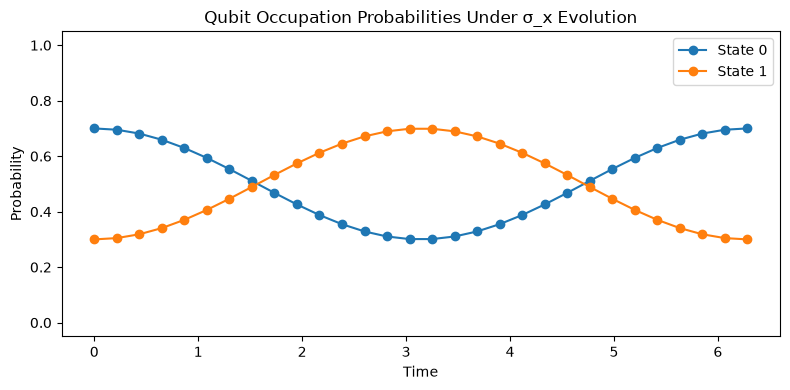

In [7]:
# Evolve the stochastic state and track Born-rule probabilities over time
omega = 1.0
times_dense = np.linspace(0, 2 * np.pi, 30).tolist()
proc_dense = make_qubit_sigmax_process(omega=omega, times=times_dense)

p0_vec = density_matrix_to_stochastic_state(rho)
fig = plot_probability_evolution(proc_dense, p0_vec,
                                 title="Qubit Occupation Probabilities Under σ_x Evolution")
plt.tight_layout()
plt.show()

## Summary

- Density matrices project onto stochastic states via their diagonal
- Qubit evolution under any non-trivial Hamiltonian produces an indivisible process
- The Born rule is a natural consequence, not an extra postulate
- This is the core of Barandes' claim: quantum mechanics *is* an indivisible stochastic process

**Next:** Notebook 05 builds the payoff — a double-slit model where
interference emerges from indivisibility.